# 2. Simulation: checking the estimator against a known answer

Real data never reveals the true volatility. Here prices are simulated from a
Heston stochastic-volatility model, where the integrated variance
IV = ∫σ²(t)dt is known exactly, so the RV estimator can be checked against it
before it is applied to EUR/USD.

In [1]:
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rvol.estimators.variance import (
    cumulative_realized_variance,
    grid_realized_variances,
    realized_variance,
    subsampled_variance,
)
from rvol.simulation.heston import cumulative_integrated_variance, simulate_heston
from rvol.simulation.monte_carlo import evaluate_estimators
from rvol.simulation.noise import add_bid_ask_bounce, add_iid_log_noise
from rvol.simulation.paths import heston_paths, illustrative_path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "figures"
TRADING_DAYS = 252

## One simulated day

A Heston path over one trading day: price, instantaneous variance σ²(t), and the
running integrated variance.

integrated variance    0.000179
realized variance      0.000179
RV / IV                1.000113
dtype: float64

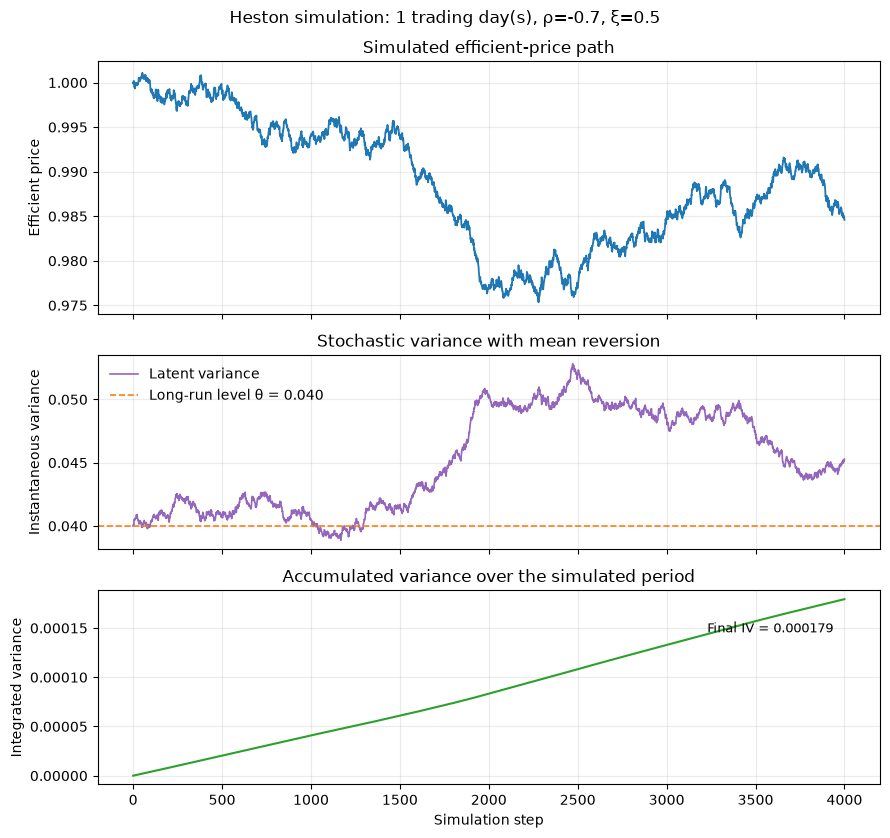

In [2]:
n_steps, theta, rho, xi = 4_000, 0.04, -0.7, 0.5
dt = 1 / TRADING_DAYS / n_steps
prices, variance, integrated_variance = simulate_heston(
    n_steps, dt, s0=1.0, v0=0.04, kappa=3.0, theta=theta, xi=xi, rho=rho,
    rng=np.random.default_rng(42),
)
steps = np.arange(len(prices))
cumulative_iv = cumulative_integrated_variance(variance, dt)

figure, (price_axis, variance_axis, iv_axis) = plt.subplots(
    3, 1, figsize=(9.0, 8.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1, 1]}
)
price_axis.plot(steps, prices, color="tab:blue", linewidth=1.3)
price_axis.set_ylabel("Efficient price")
price_axis.set_title("Simulated efficient-price path")
price_axis.grid(alpha=0.25)

variance_axis.plot(steps, variance, color="tab:purple", linewidth=1.2, label="Latent variance")
variance_axis.axhline(
    theta, color="tab:orange", linestyle="--", linewidth=1.2,
    label=f"Long-run level θ = {theta:.3f}",
)
variance_axis.legend(frameon=False)
variance_axis.set_ylabel("Instantaneous variance")
variance_axis.set_title("Stochastic variance with mean reversion")
variance_axis.grid(alpha=0.25)

iv_axis.plot(steps, cumulative_iv, color="tab:green", linewidth=1.5)
iv_axis.annotate(
    f"Final IV = {cumulative_iv[-1]:.6f}",
    xy=(steps[-1], cumulative_iv[-1]),
    xytext=(-8, -16),
    textcoords="offset points",
    ha="right",
    va="top",
    fontsize=9,
)
iv_axis.set_xlabel("Simulation step")
iv_axis.set_ylabel("Integrated variance")
iv_axis.set_title("Accumulated variance over the simulated period")
iv_axis.grid(alpha=0.25)
figure.suptitle(f"Heston simulation: 1 trading day(s), ρ={rho:g}, ξ={xi:g}")
figure.tight_layout()
figure.savefig(FIGURES / "heston_simulation.png", dpi=160)

pd.Series(
    {
        "integrated variance": integrated_variance,
        "realized variance": realized_variance(prices),
        "RV / IV": realized_variance(prices) / integrated_variance,
    }
)

## From prices to realized variance

RV is built in three steps: log returns, their squares, and the running sum.

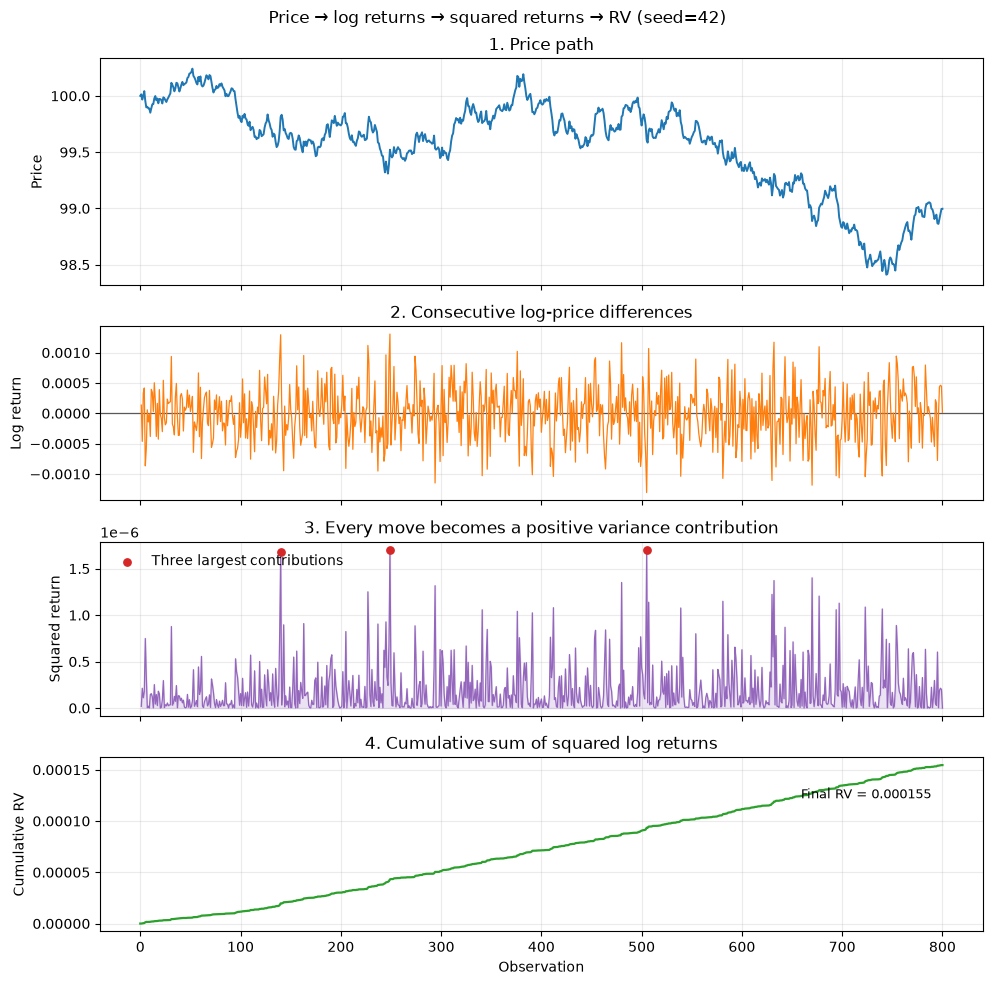

In [3]:
n_steps = 800
dt = 1 / TRADING_DAYS / n_steps
prices, variance, integrated_variance = simulate_heston(
    n_steps, dt, s0=100.0, rng=np.random.default_rng(42)
)
log_returns = np.diff(np.log(prices))
squared_returns = log_returns**2
cumulative_rv = cumulative_realized_variance(prices)
price_steps = np.arange(len(prices))
return_steps = price_steps[1:]

figure, (price_axis, return_axis, squared_axis, cumulative_axis) = plt.subplots(
    4, 1, figsize=(10.0, 10.0), sharex=True, gridspec_kw={"height_ratios": [1.3, 1, 1, 1]}
)
price_axis.plot(price_steps, prices, color="tab:blue", linewidth=1.4)
price_axis.set_ylabel("Price")
price_axis.set_title("1. Price path")
price_axis.grid(alpha=0.25)

return_axis.axhline(0, color="0.35", linewidth=0.9)
return_axis.plot(return_steps, log_returns, color="tab:orange", linewidth=0.9)
return_axis.set_ylabel("Log return")
return_axis.set_title("2. Consecutive log-price differences")
return_axis.grid(alpha=0.25)

squared_axis.plot(return_steps, squared_returns, color="tab:purple", linewidth=0.9)
squared_axis.fill_between(return_steps, 0, squared_returns, color="tab:purple", alpha=0.18)
largest = np.argsort(squared_returns)[-3:]
squared_axis.scatter(
    return_steps[largest], squared_returns[largest], color="tab:red", s=28, zorder=3,
    label="Three largest contributions",
)
squared_axis.set_ylabel("Squared return")
squared_axis.set_title("3. Every move becomes a positive variance contribution")
squared_axis.grid(alpha=0.25)
squared_axis.legend(frameon=False, loc="upper left")

cumulative_axis.plot(price_steps, cumulative_rv, color="tab:green", linewidth=1.6)
cumulative_axis.annotate(
    f"Final RV = {cumulative_rv[-1]:.6f}",
    xy=(price_steps[-1], cumulative_rv[-1]),
    xytext=(-8, -16),
    textcoords="offset points",
    ha="right",
    va="top",
    fontsize=9,
)
cumulative_axis.set_xlabel("Observation")
cumulative_axis.set_ylabel("Cumulative RV")
cumulative_axis.set_title("4. Cumulative sum of squared log returns")
cumulative_axis.grid(alpha=0.25)
figure.suptitle("Price → log returns → squared returns → RV (seed=42)")
figure.tight_layout()
figure.savefig(FIGURES / "returns_and_rv.png", dpi=160)

The cumulative RV tracks the true cumulative IV through the day:

true IV    0.000159
RV         0.000155
gap       -0.000005
dtype: float64

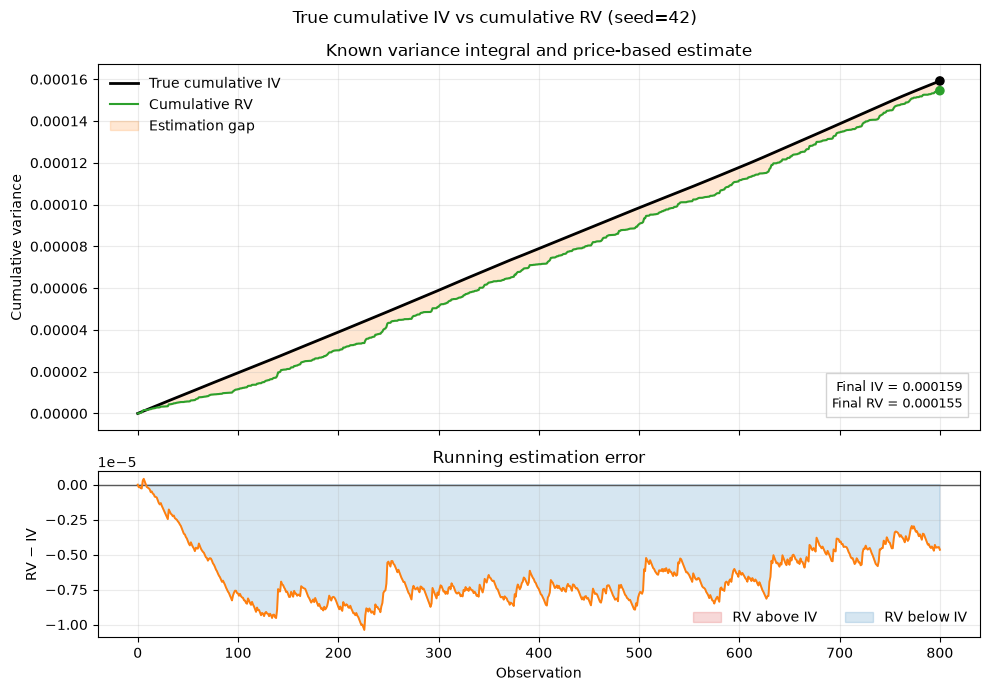

In [4]:
cumulative_iv = cumulative_integrated_variance(variance, dt)
difference = cumulative_rv - cumulative_iv

figure, (comparison_axis, difference_axis) = plt.subplots(
    2, 1, figsize=(10.0, 7.0), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]}
)
comparison_axis.plot(price_steps, cumulative_iv, color="black", linewidth=2.0,
                     label="True cumulative IV")
comparison_axis.plot(price_steps, cumulative_rv, color="tab:green", linewidth=1.5,
                     label="Cumulative RV")
comparison_axis.fill_between(price_steps, cumulative_iv, cumulative_rv, color="tab:orange",
                             alpha=0.18, label="Estimation gap")
comparison_axis.scatter(
    [price_steps[-1], price_steps[-1]], [cumulative_iv[-1], cumulative_rv[-1]],
    color=["black", "tab:green"], s=35, zorder=3,
)
comparison_axis.set_ylabel("Cumulative variance")
comparison_axis.set_title("Known variance integral and price-based estimate")
comparison_axis.grid(alpha=0.25)
comparison_axis.legend(frameon=False, loc="upper left")
comparison_axis.text(
    0.98, 0.05,
    f"Final IV = {cumulative_iv[-1]:.6f}\nFinal RV = {cumulative_rv[-1]:.6f}",
    transform=comparison_axis.transAxes, ha="right", va="bottom", fontsize=9,
    bbox={"facecolor": "white", "edgecolor": "0.8", "alpha": 0.85},
)

difference_axis.axhline(0, color="0.35", linewidth=1.0)
difference_axis.plot(price_steps, difference, color="tab:orange", linewidth=1.4)
difference_axis.fill_between(price_steps, 0, difference, where=difference >= 0,
                             color="tab:red", alpha=0.18, label="RV above IV")
difference_axis.fill_between(price_steps, 0, difference, where=difference < 0,
                             color="tab:blue", alpha=0.18, label="RV below IV")
difference_axis.set_xlabel("Observation")
difference_axis.set_ylabel("RV − IV")
difference_axis.set_title("Running estimation error")
difference_axis.grid(alpha=0.25)
difference_axis.legend(frameon=False, loc="best", ncols=2)
figure.suptitle("True cumulative IV vs cumulative RV (seed=42)")
figure.tight_layout()
figure.savefig(FIGURES / "cumulative_iv_vs_rv.png", dpi=160)

pd.Series({"true IV": integrated_variance, "RV": cumulative_rv[-1],
           "gap": cumulative_rv[-1] - integrated_variance})

## A year of daily RV

Volatility clusters: calm and turbulent stretches persist, which is what makes
tomorrow's RV forecastable from today's.

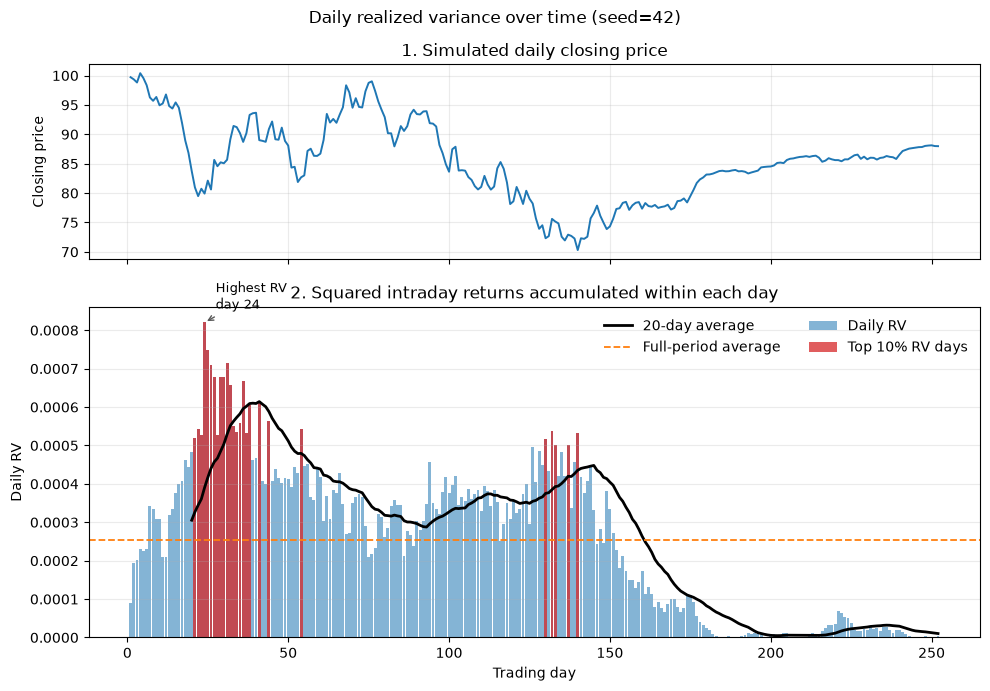

In [5]:
days, per_day, window = TRADING_DAYS, 96, 20
prices, _, _ = simulate_heston(
    days * per_day, 1 / TRADING_DAYS / per_day, s0=100.0, rng=np.random.default_rng(42)
)
daily_rv = np.sum(np.diff(np.log(prices)).reshape(days, per_day) ** 2, axis=1)
daily_close = prices[per_day::per_day]
day_numbers = np.arange(1, days + 1)
rolling_mean = pd.Series(daily_rv).rolling(window).mean().to_numpy()
high_days = daily_rv >= np.quantile(daily_rv, 0.9)
highest = int(np.argmax(daily_rv))

figure, (price_axis, rv_axis) = plt.subplots(
    2, 1, figsize=(10.0, 7.0), sharex=True, gridspec_kw={"height_ratios": [1, 1.7]}
)
price_axis.plot(day_numbers, daily_close, color="tab:blue", linewidth=1.4)
price_axis.set_ylabel("Closing price")
price_axis.set_title("1. Simulated daily closing price")
price_axis.grid(alpha=0.25)

rv_axis.bar(day_numbers, daily_rv, color="tab:blue", alpha=0.55, width=0.9, label="Daily RV")
rv_axis.bar(day_numbers[high_days], daily_rv[high_days], color="tab:red", alpha=0.75,
            width=0.9, label="Top 10% RV days")
rv_axis.plot(day_numbers, rolling_mean, color="black", linewidth=2.0,
             label=f"{window}-day average")
rv_axis.axhline(np.mean(daily_rv), color="tab:orange", linestyle="--", linewidth=1.3,
                label="Full-period average")
rv_axis.annotate(
    f"Highest RV\nday {day_numbers[highest]}",
    xy=(day_numbers[highest], daily_rv[highest]),
    xytext=(8, 10), textcoords="offset points", fontsize=9,
    arrowprops={"arrowstyle": "->", "color": "0.35"},
)
rv_axis.set_xlabel("Trading day")
rv_axis.set_ylabel("Daily RV")
rv_axis.set_title("2. Squared intraday returns accumulated within each day")
rv_axis.grid(axis="y", alpha=0.25)
rv_axis.legend(frameon=False, loc="upper right", ncols=2)
figure.suptitle("Daily realized variance over time (seed=42)")
figure.tight_layout()
figure.savefig(FIGURES / "daily_rv.png", dpi=160)

## Sampling grids

The same path sampled every 5 observations from different starting points gives
different RVs. Averaging over all grids (subsampling) uses every observation.

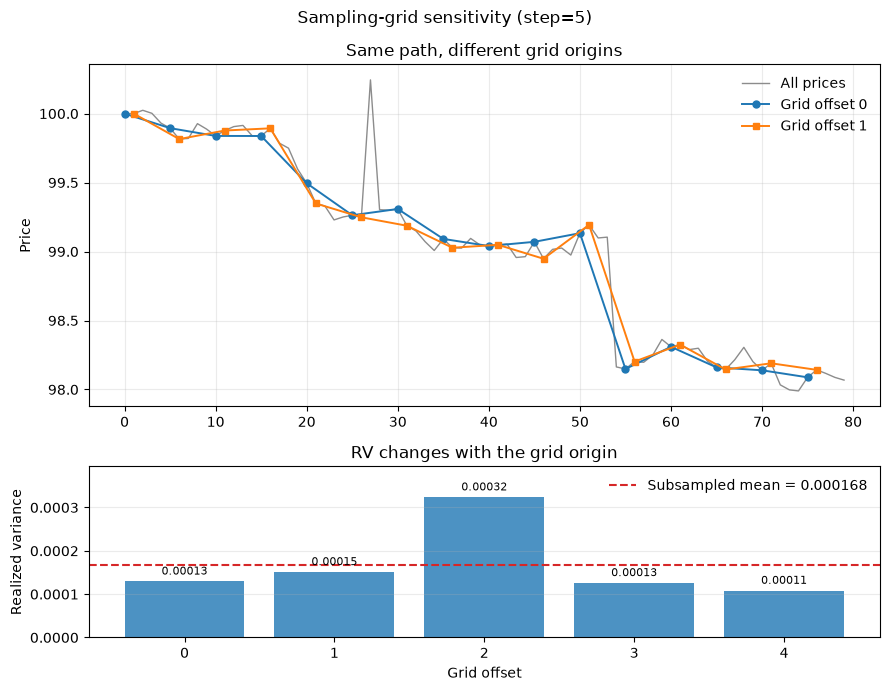

In [6]:
step = 5
prices = illustrative_path(80, seed=7)
grid_rv = grid_realized_variances(prices, step)
offsets = np.arange(step)
observations = np.arange(len(prices))

figure, (path_axis, rv_axis) = plt.subplots(
    2, 1, figsize=(9.0, 7.0), gridspec_kw={"height_ratios": [2, 1]}
)
path_axis.plot(observations, prices, color="0.55", linewidth=1, label="All prices")
for color, marker, offset in zip(("tab:blue", "tab:orange"), ("o", "s"), (0, 1), strict=True):
    path_axis.plot(observations[offset::step], prices[offset::step], color=color,
                   marker=marker, linewidth=1.4, markersize=5, label=f"Grid offset {offset}")
path_axis.set_ylabel("Price")
path_axis.set_title("Same path, different grid origins")
path_axis.grid(alpha=0.25)
path_axis.legend(frameon=False)

bars = rv_axis.bar(offsets, grid_rv, color="tab:blue", alpha=0.8)
rv_axis.axhline(grid_rv.mean(), color="tab:red", linestyle="--", linewidth=1.5,
                label=f"Subsampled mean = {grid_rv.mean():.6f}")
rv_axis.set_ylim(0, float(np.max(grid_rv)) * 1.22)
rv_axis.set_xlabel("Grid offset")
rv_axis.set_ylabel("Realized variance")
rv_axis.set_title("RV changes with the grid origin")
rv_axis.set_xticks(offsets)
rv_axis.grid(axis="y", alpha=0.25)
rv_axis.legend(frameon=False)
for bar, estimate in zip(bars, grid_rv, strict=True):
    rv_axis.annotate(f"{estimate:.5f}", xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                     xytext=(0, 3), textcoords="offset points", ha="center", va="bottom",
                     fontsize=8)
figure.suptitle(f"Sampling-grid sensitivity (step={step})")
figure.tight_layout()
figure.savefig(FIGURES / "sampling_grids.png", dpi=160)

## Bid–ask bounce

Trades alternate between bid and ask around the efficient price. Each switch adds
a return that is pure noise, so RV computed from trade prices is inflated.

mid RV          0.000004
trade RV        0.000017
RV inflation    4.232469
dtype: float64

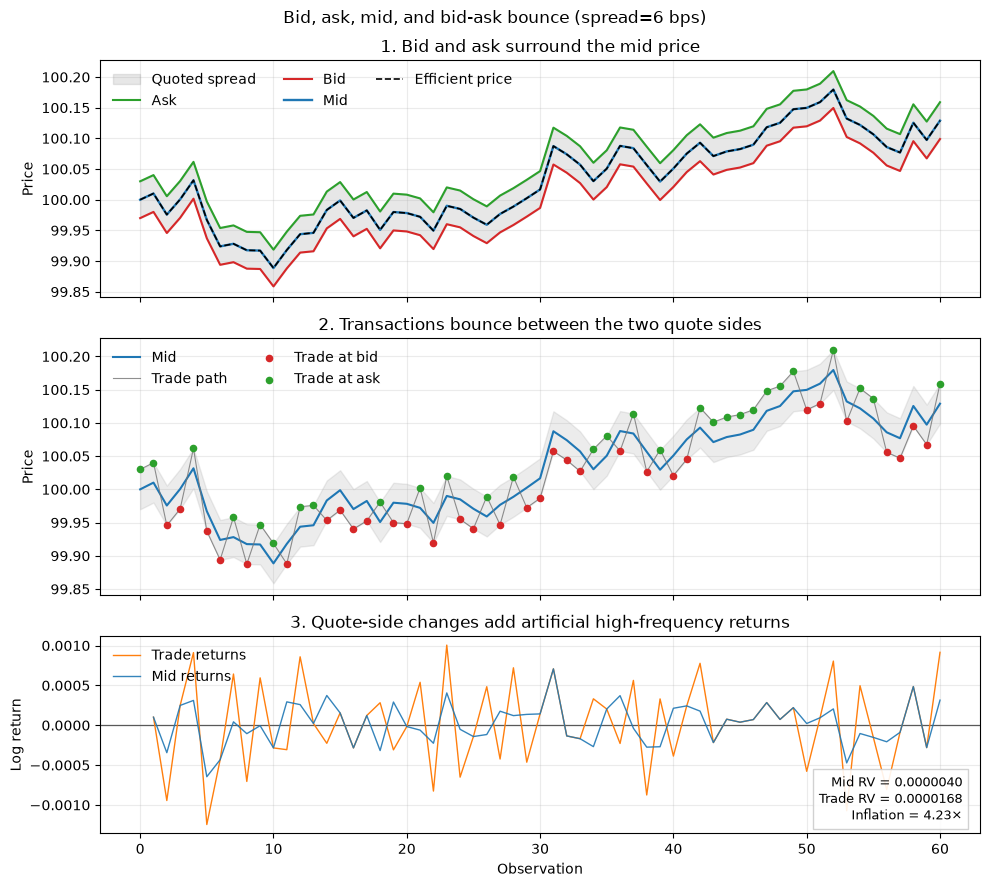

In [7]:
n_steps, spread_bps = 60, 6.0
efficient, _, _ = simulate_heston(
    n_steps, 1 / 24 / TRADING_DAYS / n_steps, s0=100.0, rng=np.random.default_rng(42)
)
half_spread = spread_bps / 2 / 10_000
bid, ask = efficient * np.exp(-half_spread), efficient * np.exp(half_spread)
mid = 0.5 * (bid + ask)
trades = add_bid_ask_bounce(efficient, half_spread, rng=np.random.default_rng(43))
mid_rv, trade_rv = realized_variance(mid), realized_variance(trades)
steps = np.arange(n_steps + 1)
trade_at_ask = np.abs(trades - ask) <= np.abs(trades - bid)

figure, (quote_axis, trade_axis, return_axis) = plt.subplots(
    3, 1, figsize=(10.0, 9.0), sharex=True, gridspec_kw={"height_ratios": [1.2, 1.3, 1]}
)
quote_axis.fill_between(steps, bid, ask, color="tab:gray", alpha=0.18, label="Quoted spread")
quote_axis.plot(steps, ask, color="tab:green", label="Ask")
quote_axis.plot(steps, bid, color="tab:red", label="Bid")
quote_axis.plot(steps, mid, color="tab:blue", linewidth=1.7, label="Mid")
quote_axis.plot(steps, efficient, color="black", linewidth=1.2, linestyle="--",
                label="Efficient price")
quote_axis.set_ylabel("Price")
quote_axis.set_title("1. Bid and ask surround the mid price")
quote_axis.grid(alpha=0.25)
quote_axis.legend(frameon=False, loc="best", ncols=3)

trade_axis.fill_between(steps, bid, ask, color="tab:gray", alpha=0.14)
trade_axis.plot(steps, mid, color="tab:blue", linewidth=1.5, label="Mid")
trade_axis.plot(steps, trades, color="0.45", linewidth=0.8, alpha=0.8, label="Trade path")
trade_axis.scatter(steps[~trade_at_ask], trades[~trade_at_ask], color="tab:red", s=20,
                   zorder=3, label="Trade at bid")
trade_axis.scatter(steps[trade_at_ask], trades[trade_at_ask], color="tab:green", s=20,
                   zorder=3, label="Trade at ask")
trade_axis.set_ylabel("Price")
trade_axis.set_title("2. Transactions bounce between the two quote sides")
trade_axis.grid(alpha=0.25)
trade_axis.legend(frameon=False, loc="best", ncols=2)

return_axis.axhline(0, color="0.35", linewidth=0.9)
return_axis.plot(steps[1:], np.diff(np.log(trades)), color="tab:orange", linewidth=1.0,
                 label="Trade returns")
return_axis.plot(steps[1:], np.diff(np.log(mid)), color="tab:blue", linewidth=1.0, alpha=0.9,
                 label="Mid returns")
return_axis.text(
    0.98, 0.05,
    f"Mid RV = {mid_rv:.7f}\nTrade RV = {trade_rv:.7f}\nInflation = {trade_rv / mid_rv:.2f}×",
    transform=return_axis.transAxes, ha="right", va="bottom", fontsize=9,
    bbox={"facecolor": "white", "edgecolor": "0.8", "alpha": 0.9},
)
return_axis.set_xlabel("Observation")
return_axis.set_ylabel("Log return")
return_axis.set_title("3. Quote-side changes add artificial high-frequency returns")
return_axis.grid(alpha=0.25)
return_axis.legend(frameon=False, loc="upper left")
figure.suptitle(f"Bid, ask, mid, and bid-ask bounce (spread={spread_bps:g} bps)")
figure.tight_layout()
figure.savefig(FIGURES / "bid_ask_bounce.png", dpi=160)

pd.Series({"mid RV": mid_rv, "trade RV": trade_rv, "RV inflation": trade_rv / mid_rv})

## Monte Carlo: bias and RMSE

Over 100 simulated days, with and without observation noise (1 bp per
observation), compare plain RV with RV averaged over 20 sampling grids.

In [8]:
n_steps, noise_sd, replications = 4_000, 1e-4, 100
dt = 1 / TRADING_DAYS / n_steps
estimators = {
    "Naive RV": realized_variance,
    "Subsampled RV": partial(subsampled_variance, step=20),
}
scenarios = {
    "Clean": evaluate_estimators(
        heston_paths(n_steps, dt, xi=0.0), estimators, n_replications=replications, seed=12
    ),
    "Noisy": evaluate_estimators(
        heston_paths(n_steps, dt, xi=0.0, noise_sd=noise_sd),
        estimators, n_replications=replications, seed=13,
    ),
}
results = pd.DataFrame(
    [
        {
            "scenario": scenario,
            "estimator": summary.estimator,
            "relative bias": summary.relative_bias,
            "relative RMSE": summary.relative_rmse,
        }
        for scenario, summaries in scenarios.items()
        for summary in summaries
    ]
)
results

,scenario,estimator,relative bias,relative RMSE
0,Clean,Naive RV,0.003821,0.024274
1,Clean,Subsampled RV,0.001331,0.082867
2,Noisy,Naive RV,0.508647,0.510190
3,Noisy,Subsampled RV,0.017330,0.088124


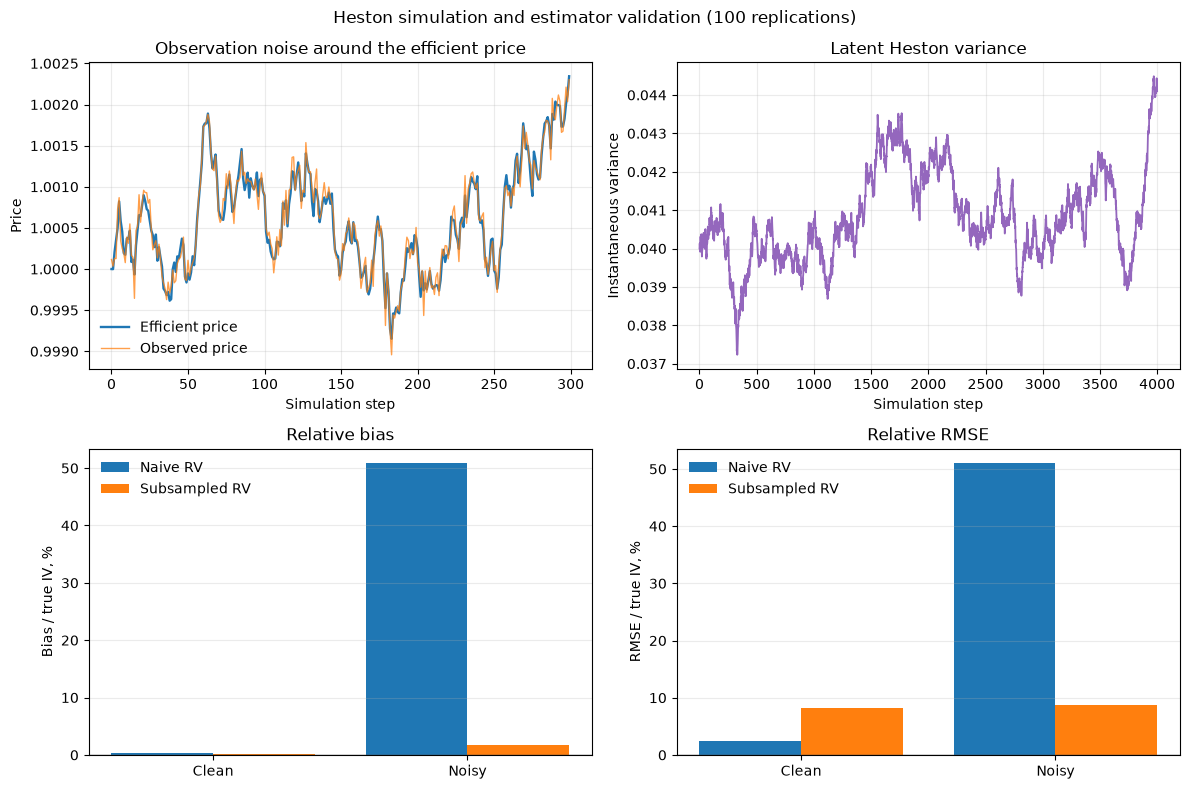

In [9]:
rng = np.random.default_rng(12)
efficient, variance, _ = simulate_heston(n_steps, dt, rng=rng)
observed = add_iid_log_noise(efficient, noise_sd, rng)

figure, axes = plt.subplots(2, 2, figsize=(12.0, 8.0))
price_axis, variance_axis, bias_axis, rmse_axis = axes.flat
zoom = np.arange(300)
price_axis.plot(zoom, efficient[:300], label="Efficient price", linewidth=1.7)
price_axis.plot(zoom, observed[:300], label="Observed price", linewidth=1, alpha=0.75)
price_axis.set_xlabel("Simulation step")
price_axis.set_ylabel("Price")
price_axis.set_title("Observation noise around the efficient price")
price_axis.grid(alpha=0.25)
price_axis.legend(frameon=False)

variance_axis.plot(np.arange(len(variance)), variance, color="tab:purple", linewidth=1.3)
variance_axis.set_xlabel("Simulation step")
variance_axis.set_ylabel("Instantaneous variance")
variance_axis.set_title("Latent Heston variance")
variance_axis.grid(alpha=0.25)

positions = np.arange(len(scenarios))
width = 0.8 / len(estimators)
colors = ("tab:blue", "tab:orange")
for index, (estimator, color) in enumerate(zip(estimators, colors, strict=True)):
    rows = results.loc[results["estimator"] == estimator].set_index("scenario").loc[list(scenarios)]
    shift = (index - (len(estimators) - 1) / 2) * width
    for axis, column in ((bias_axis, "relative bias"), (rmse_axis, "relative RMSE")):
        axis.bar(positions + shift, rows[column] * 100, width, label=estimator, color=color)
for axis, ylabel, title in (
    (bias_axis, "Bias / true IV, %", "Relative bias"),
    (rmse_axis, "RMSE / true IV, %", "Relative RMSE"),
):
    axis.axhline(0, color="0.35", linewidth=1)
    axis.set_xticks(positions, list(scenarios))
    axis.set_ylabel(ylabel)
    axis.set_title(title)
    axis.grid(axis="y", alpha=0.25)
    axis.legend(frameon=False)
figure.suptitle(f"Heston simulation and estimator validation ({replications} replications)")
figure.tight_layout()
figure.savefig(FIGURES / "simulation_overview.png", dpi=160)

**Conclusion.** Without noise, RV on every observation is essentially unbiased
for IV and the most precise estimator, because it uses all the data. With noise
it is biased upward by about half, since every extra return adds noise variance.
RV on sparser grids, averaged over all 20 starting points, cuts that bias to a
few percent at the cost of precision. On EUR/USD mid quotes the noise is small
(notebook 1), so plain 5-minute RV is used directly.